# Spaceship titanic

Benvinguts a l'any 2912, on les vostres habilitats en ciència de dades són necessàries per resoldre un misteri còsmic. Hem rebut una transmissió des de quatre anys llum de distància i la situació no pinta gens bé.

La *Spaceship Titanic* era una nau de passatgers interestel·lar que va salpar fa un mes. Amb gairebé 13.000 passatgers a bord, la nau va emprendre el seu viatge inaugural transportant emigrants del nostre sistema solar cap a tres exoplanetes recentment habitables que orbiten estrelles properes.

Mentre vorejava Alpha Centauri, de camí cap a la seva primera destinació —el tòrrid 55 Cancri E—, la *Spaceship Titanic* va topar, per sorpresa, amb una anomalia espaciotemporal amagada dins d'un núvol de pols. Malauradament, va córrer una sort semblant a la del seu homònim de fa 1.000 anys. Tot i que la nau va romandre intacta, gairebé la meitat dels passatgers van ser transportats a una dimensió alternativa!

Font:
https://www.kaggle.com/competitions/spaceship-titanic/data

## Dataset Description

In this competition your task is to predict whether a passenger was transported to an alternate dimension during the Spaceship Titanic's collision with the spacetime anomaly. To help you make these predictions, you're given a set of personal records recovered from the ship's damaged computer system.
File and Data Field Descriptions

* train.csv - Personal records for about two-thirds (~8700) of the passengers, to be used as training data.
    * PassengerId - A unique Id for each passenger. Each Id takes the form gggg_pp where gggg indicates a group the passenger is travelling with and pp is their number within the group. People in a group are often family members, but not always.
    * HomePlanet - The planet the passenger departed from, typically their planet of permanent residence.
    * CryoSleep - Indicates whether the passenger elected to be put into suspended animation for the duration of the voyage. Passengers in cryosleep are confined to their cabins.
    * Cabin - The cabin number where the passenger is staying. Takes the form deck/num/side, where side can be either P for Port or S for Starboard.
    * Destination - The planet the passenger will be debarking to.
    * Age - The age of the passenger.
    * VIP - Whether the passenger has paid for special VIP service during the voyage.
    * RoomService, FoodCourt, ShoppingMall, Spa, VRDeck - Amount the passenger has billed at each of the Spaceship Titanic's many luxury amenities.
    * Name - The first and last names of the passenger.
    * Transported - Whether the passenger was transported to another dimension. This is the target, the column you are trying to predict.
* test.csv - Personal records for the remaining one-third (~4300) of the passengers, to be used as test data. Your task is to predict the value of Transported for the passengers in this set.
* sample_submission.csv - A submission file in the correct format.
    * PassengerId - Id for each passenger in the test set.
    * Transported - The target. For each passenger, predict either True or False.

## Descripció de la tasca

Aquesta competició de Kaggle que ha eixit fa poc planteja un problema de classificació binària: Si el passatger d'una nau espacial és enviat o no a una altra dimensió. 

Òbviament les dades són sintètiques, però no trivials. Els millors participans han aconseguit bons resultats, així que es suposa que funcionarà raonablement bé. 


In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score, roc_curve
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

df_original = pd.read_csv('train.csv')  
df_original.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [38]:
df = df_original.copy()

ids = np.array(df["PassengerId"].apply(lambda pId: pId.split("_")).to_list())
df["PId"] = ids[:,1]
df["PId"] = pd.to_numeric(df["PId"], errors="coerce")
df["GId"] = ids[:,0]
df["GId"] = pd.to_numeric(df["GId"], errors="coerce")

df.loc[df["Cabin"].isnull(),"Cabin"] = "_nodefinido_/_nodefinido_/_nodefinido_"
cabins = pd.DataFrame(df["Cabin"].apply(lambda pId: pId.split("/")).to_list(), columns=["deck","num","side"])

cabins["num"] = pd.to_numeric(cabins["num"], errors="coerce").fillna(0)

df["total_spend"] = np.log( df[["RoomService","FoodCourt","ShoppingMall","Spa","VRDeck"]].sum(axis=1) +1 ) # fem el logaritme per tenir les dades acotades

df.loc[df["Name"].isnull(),"Name"] = "_nodefinido_"
names = pd.DataFrame(df["Name"].apply(lambda pId: pId.split(" ")).to_list(), columns=["name","surname"])

df = pd.concat([df,cabins,names], axis=1)

df["group_size"] = df.groupby("GId")["GId"].transform("count")
df["family_size"] = df.groupby("surname")["surname"].transform("count")

#print(df.loc[df["group_size"] == df["family_size"], ["GId","group_size","family_size"]])
df["is_family"] = np.where(df["group_size"] == df["family_size"], 1, 0)

df = df.drop(columns=["PassengerId","Cabin","Name","name","surname"])

df.head()

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,PId,GId,total_spend,deck,num,side,group_size,family_size,is_family
0,Europa,False,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,False,1,1,0.000000,B,0.0,P,1,1.0,1
1,Earth,False,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,True,1,2,6.602588,F,0.0,S,1,4.0,0
2,Europa,False,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,False,1,3,9.248021,A,0.0,S,2,6.0,0
3,Europa,False,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,False,2,3,8.551981,A,0.0,S,2,6.0,0
4,Earth,False,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,True,1,4,6.995766,F,1.0,S,1,6.0,0


In [45]:
# posen a 0 les variables nules de les columnes numèriques i a "_nodefinido_" les variables nules de les columnes categòriques
df = df.fillna({"Age":0, "RoomService":0, "FoodCourt":0, "ShoppingMall":0, "Spa":0, "VRDeck":0, "deck":"_nodefinido_", "num":0, "side":"_nodefinido_", "group_size":0, "family_size":0})
# els valors null de CryoSleep, VIP els posem a 0, ja que són variables binàries
df = df.fillna({"CryoSleep":0, "VIP":0})
# per a la variable HomePlanet, posem el valor null a "Earth", ja que és el planeta amb més passatgers
df = df.fillna({"HomePlanet":"_nodefinido_", "Destination":"_nodefinido_"})

#detectar els nan en tot el dataframe
print(df.isna().sum())

HomePlanet      0
CryoSleep       0
Destination     0
Age             0
VIP             0
RoomService     0
FoodCourt       0
ShoppingMall    0
Spa             0
VRDeck          0
Transported     0
PId             0
GId             0
total_spend     0
deck            0
num             0
side            0
group_size      0
family_size     0
is_family       0
dtype: int64


<Axes: xlabel='total_spend', ylabel='Count'>

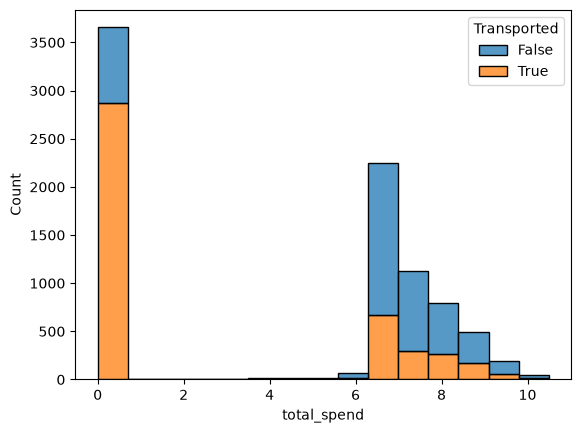

In [40]:

sns.histplot(data=df, x="total_spend", hue="Transported", multiple="stack")

<Axes: xlabel='total_spend', ylabel='Count'>

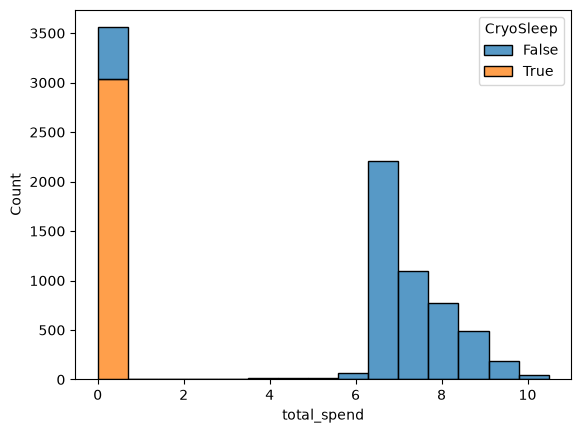

In [10]:
sns.histplot(data=df, x="total_spend", hue="CryoSleep", multiple="stack")

<Axes: xlabel='CryoSleep', ylabel='Count'>

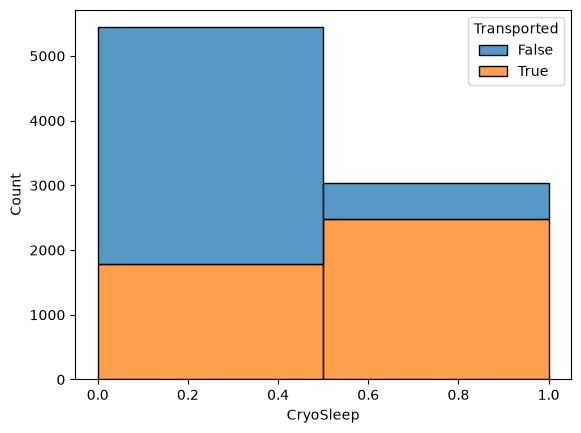

In [11]:
sns.histplot(data=df, x="CryoSleep", hue="Transported", multiple="stack", bins=2)

Hi ha molta gent que no ha gastat res, la majoria dels que no gasten són els criogenitzats dels qual tots han gastat 0. Els que gasten ho fan la majoria a partir de certa quantitat. 

La majoria dels que no han gastat res han sigut transportats. 

La majoria dels criogenitzats han sigut transportats. No sabem si per la seua situació o per no gastar. 

Exercici 1:

Raona les millors adaptacions que es poden fer al dataset per aprofitar millor l'informació disponible. Pensa en les columnes extra que es poden extraure i en què fer amb les dades que falten. Pensa per a què podrien servir les dades de test.csv si no tenen target.    

Exercici 2: 

Fes un anàlisi de les distintes correlacions entre les variables i l'objectiu. Interpreta quines variables podrien servir en cas d'una classificació amb mètodes lineals. Fes un anàlisi de la distribució de les variables en relació a la variable target. 

In [46]:
#df.info()

df_onehot = pd.get_dummies(df, columns=["HomePlanet","Destination","deck","side"], drop_first=True)
df_onehot.head()

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,PId,...,deck_B,deck_C,deck_D,deck_E,deck_F,deck_G,deck_T,deck__nodefinido_,side_S,side__nodefinido_
0,False,39.0,False,0.0,0.0,0.0,0.0,0.0,False,1,...,True,False,False,False,False,False,False,False,False,False
1,False,24.0,False,109.0,9.0,25.0,549.0,44.0,True,1,...,False,False,False,False,True,False,False,False,True,False
2,False,58.0,True,43.0,3576.0,0.0,6715.0,49.0,False,1,...,False,False,False,False,False,False,False,False,True,False
3,False,33.0,False,0.0,1283.0,371.0,3329.0,193.0,False,2,...,False,False,False,False,False,False,False,False,True,False
4,False,16.0,False,303.0,70.0,151.0,565.0,2.0,True,1,...,False,False,False,False,True,False,False,False,True,False


In [37]:
print(df_onehot.columns)

Index(['CryoSleep', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall',
       'Spa', 'VRDeck', 'Transported', 'PId', 'GId', 'total_spend', 'num',
       'group_size', 'family_size', 'is_family', 'HomePlanet_Europa',
       'HomePlanet_Mars', 'HomePlanet__nodefinido_',
       'Destination_PSO J318.5-22', 'Destination_TRAPPIST-1e',
       'Destination__nodefinido_', 'deck_B', 'deck_C', 'deck_D', 'deck_E',
       'deck_F', 'deck_G', 'deck_T', 'deck__nodefinido_', 'side_S',
       'side__nodefinido_'],
      dtype='object')


<Axes: title={'center': 'Correlació amb la variable Transported'}>

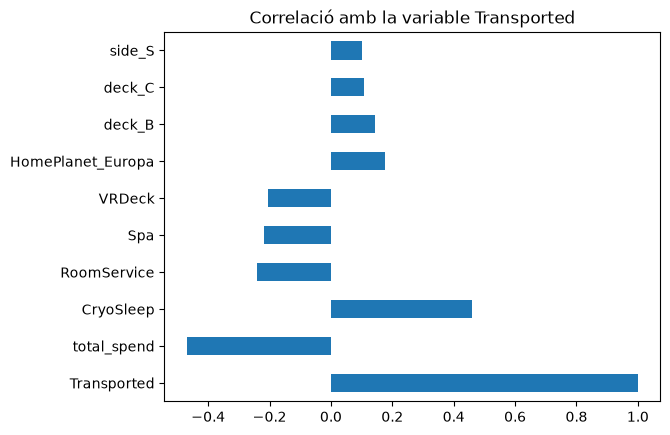

In [60]:
corr = df_onehot.corr()["Transported"].sort_values(ascending=False, key=lambda x: abs(x))[:10]  # Excloem la correlació amb si mateix
corr.plot(kind="barh", title="Correlació amb la variable Transported")

Text(0.5, 1.0, 'Mapa de calor de correlació entre variables')

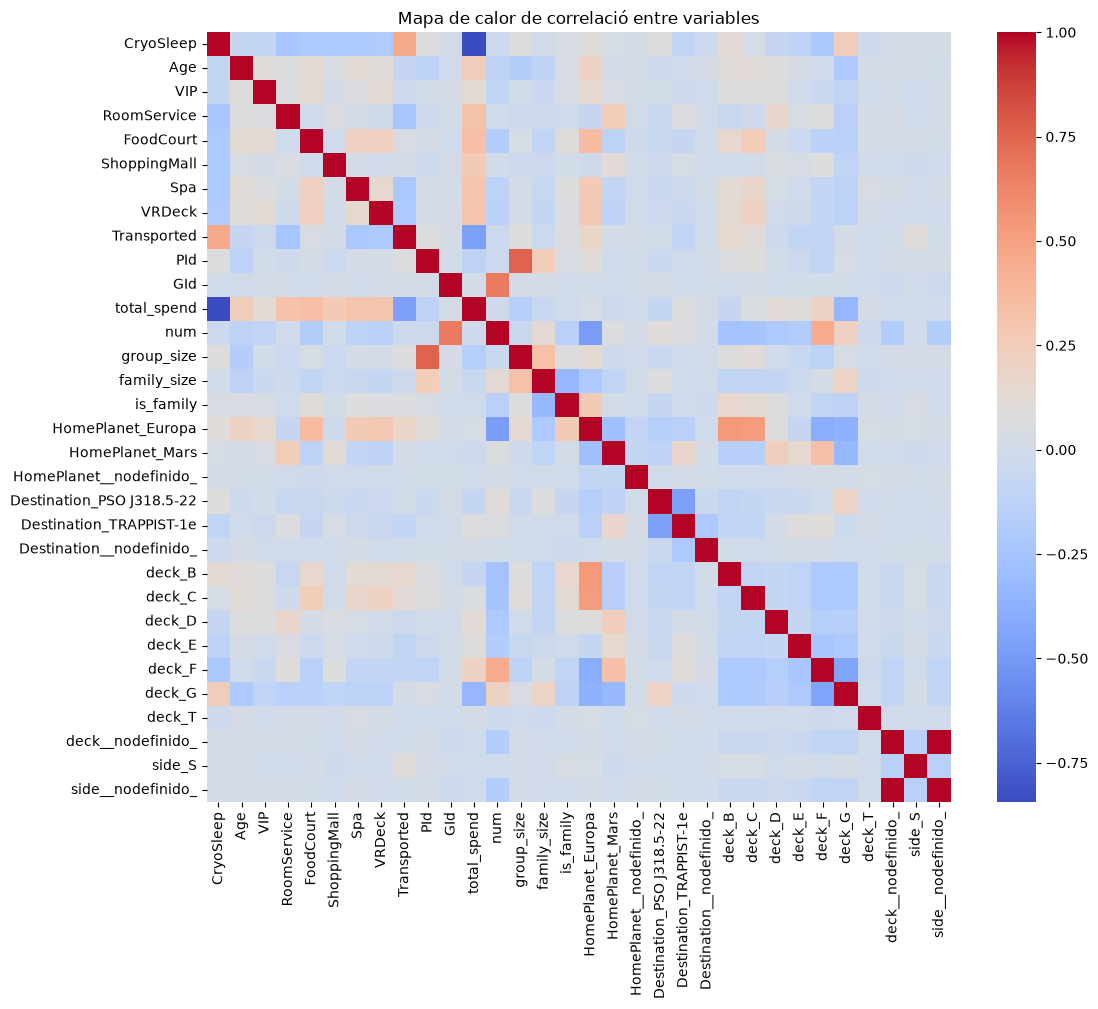

In [63]:
# Detecció de variables amb alta correlació entre elles. 
plt.figure(figsize=(12, 10))
sns.heatmap(df_onehot.corr(), annot=False, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Mapa de calor de correlació entre variables")

Exercici 3: 

Fes entrenaments lleugers de models simples de totes les famílies com `Gaussian Naive Bayes`, `LogisticRegression` o `DecisionTreeClassifier`. Interpreta els resultats de `classification_report` en relació al tipus de model. 

Model: GaussianNB
Accuracy: 0.765382403680276
Precision: 0.7175925925925926
Recall: 0.8826879271070615
F1 Score: 0.7916241062308478
Classification Report:
               precision    recall  f1-score   support

       False       0.84      0.65      0.73       861
        True       0.72      0.88      0.79       878

    accuracy                           0.77      1739
   macro avg       0.78      0.76      0.76      1739
weighted avg       0.78      0.77      0.76      1739



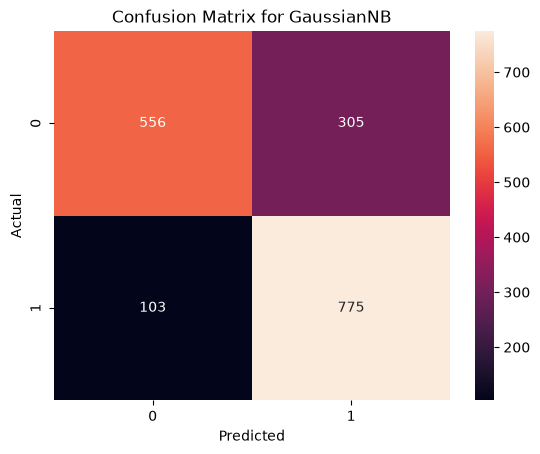

Model: LogisticRegression
Accuracy: 0.7044278320874066
Precision: 0.6410852713178294
Recall: 0.9419134396355353
F1 Score: 0.7629151291512916
Classification Report:
               precision    recall  f1-score   support

       False       0.89      0.46      0.61       861
        True       0.64      0.94      0.76       878

    accuracy                           0.70      1739
   macro avg       0.76      0.70      0.69      1739
weighted avg       0.76      0.70      0.69      1739



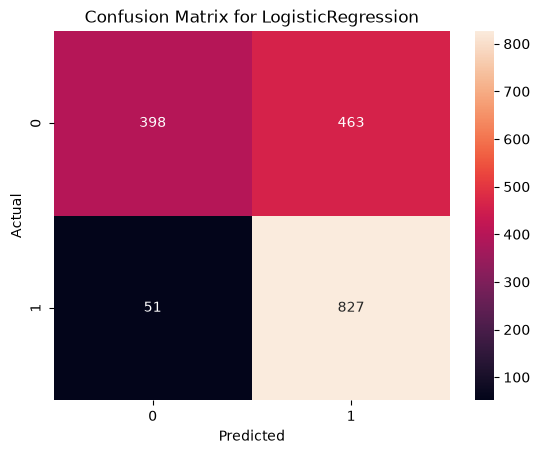

Model: DecisionTreeClassifier
Accuracy: 0.7481311098332375
Precision: 0.7428256070640177
Recall: 0.7665148063781321
F1 Score: 0.7544843049327354
Classification Report:
               precision    recall  f1-score   support

       False       0.75      0.73      0.74       861
        True       0.74      0.77      0.75       878

    accuracy                           0.75      1739
   macro avg       0.75      0.75      0.75      1739
weighted avg       0.75      0.75      0.75      1739



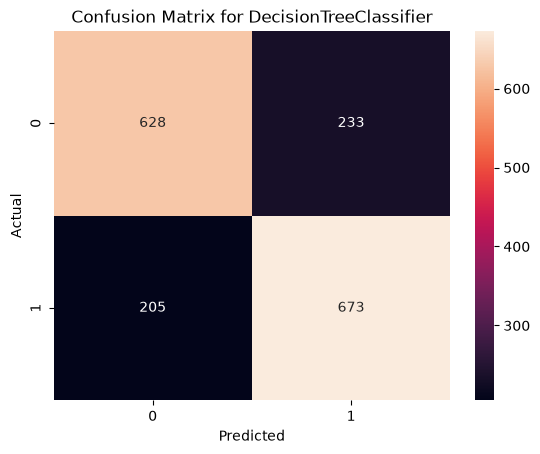

In [50]:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,classification_report
import seaborn as sns

from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import SGDClassifier

X = df_onehot.drop(columns=["Transported"])
y = df_onehot["Transported"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


models = {
    "GaussianNB": GaussianNB(),
    "LogisticRegression": SGDClassifier(loss="log_loss", max_iter=1000),
    "DecisionTreeClassifier": DecisionTreeClassifier()
}


for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"Model: {model_name}")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1 Score:", f1_score(y_test, y_pred))
    print("Classification Report:\n", classification_report(y_test, y_pred))

    # Plot confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d')
    plt.title(f'Confusion Matrix for {model_name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()


Exercici 4: 

Tria algun dels models moderns basats en ensembles d'arbres de classificació. Pots fer proves i/o justificar l'elecció en base al tipus de problemes per al quals estan dissenyats i el tipus i quantitat de dades. 
Planifica un entrenament amb tot: Pipelines, adaptacions del dataset, CV, Grid Search, entrenament final, mètriques i interpretació de totes les mètriques. 


In [67]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score

#clf = RandomForestClassifier(random_state=42)
clf = HistGradientBoostingClassifier()
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print("accuracy score: ", accuracy_score(y_test, y_pred))
print("accuracy score train: ", accuracy_score(y_train, y_train))


accuracy score:  0.8085106382978723
accuracy score train:  1.0


In [68]:
param_grid = {
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_iter': [100, 200, 300],
    'max_depth': [None, 3, 5, 10],
    'min_samples_leaf': [5,20, 100],
    'l2_regularization': [0.0, 0.01, 0.1, 1.0]
}

# Configuració del GridSearchCV
grid_search = GridSearchCV(
    estimator=clf,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    return_train_score=True,
    verbose=0
)

grid_search.fit(X_train, y_train)

print("Millors paràmetres trobats: %s" % grid_search.best_params_)
print("Millor F1 de validació: %0.2f" % grid_search.best_score_)

Millors paràmetres trobats: {'l2_regularization': 0.01, 'learning_rate': 0.05, 'max_depth': 3, 'max_iter': 200, 'min_samples_leaf': 100}
Millor F1 de validació: 0.82


accuracy score:  0.7952846463484762
Accuracy: 0.7952846463484762
Precision: 0.770746887966805
Recall: 0.8462414578587699
F1 Score: 0.8067318132464713
Classification Report:
               precision    recall  f1-score   support

       False       0.83      0.74      0.78       861
        True       0.77      0.85      0.81       878

    accuracy                           0.80      1739
   macro avg       0.80      0.79      0.79      1739
weighted avg       0.80      0.80      0.79      1739



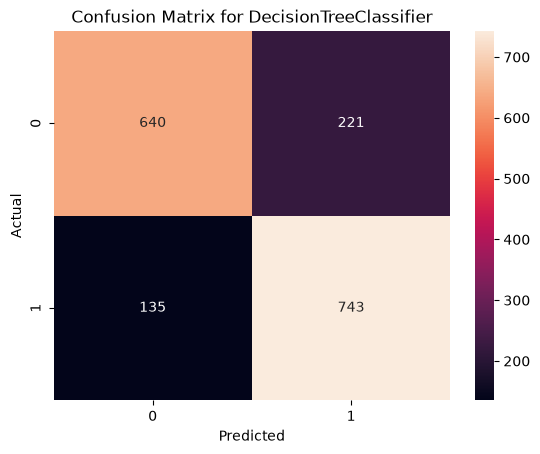

In [70]:
best_params = grid_search.best_params_
best_clf = HistGradientBoostingClassifier(**best_params)
best_clf.fit(X_train, y_train)
y_pred = best_clf.predict(X_test)
print("accuracy score: ", accuracy_score(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

    # Plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.title(f'Confusion Matrix for {model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


Exercici 5:

Fes un anàlisi SHAP de l'importància i influència de les variables. 

In [73]:
print(X_train.select_dtypes(include=['object', 'category']).columns)

Index(['CryoSleep', 'VIP'], dtype='object')


In [72]:
import shap
import pandas as pd


explainer = shap.Explainer(best_clf, X_train)

shap_values = explainer(X_test)

shap.summary_plot(shap_values, X_test)

Background dataset has 6954 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=6954 when initializing the masker.
Found a NULL input array in _cext_dense_tree_update_weights!


TypeError: Cannot cast array data from dtype('O') to dtype('float64') according to the rule 'safe'

In [ ]:
shap.summary_plot(shap_values, X_val, plot_type="bar")